# Clustering (Role B · Cluster patient experiences per condition)

Every review in the four scope conditions is vectorised with **TF-IDF** (bigrams, log-TF, 20 k features) and projected with **Latent Semantic Analysis** (TruncatedSVD + L2 normalisation, 100 dimensions).  We then cluster with **k-means** and **DBSCAN** and choose *k* by minimising the **Davies-Bouldin index**.

Results answer research question 1: *Can patient reviews be grouped into common experience types (e.g. "weight gain", "mood swings", "worked well, no side effects")?*

## Pipeline overview

| Step | Section | What it does |
|---|---|---|
| Load & scope | B1 | Load Role A's clean data, keep the four conditions |
| TF-IDF vectorisation | B2 | One vectoriser per condition (20k features, bigrams, `sublinear_tf=True`, English stop words removed) |
| Dimensionality reduction | B3 | TruncatedSVD (100 components, LSA) + L2 normalisation |
| K-means sweep | B4 | Sweep k = 2 … 12 per condition, pick k_best = argmin(Davies-Bouldin) |
| DBSCAN | B5 | kNN distance plot to choose eps, then grid search over eps × min_samples |
| Compare | B6 | Side-by-side DB scores for k-means vs DBSCAN |
| Cluster profiles | B7 | Top-10 TF-IDF terms, mean rating, sample reviews, heatmap, 2D scatter |
| Rating vs cluster | B8 | Kruskal-Wallis test + boxplot per condition |
| Save outputs | B9 | Parquet, CSV and JSON for the report |

### Outputs

| File | Used by |
|---|---|
| `outputs/cluster_assignments.parquet` | Everyone — join to any table on `review_id` |
| `outputs/cluster_profiles.csv` | Report: top terms and mean rating per cluster |
| `outputs/figures/` | Report: `kmeans_sweep`, `dbscan_knn_distances`, `kmeans_scatter`, `cluster_terms_*`, `rating_by_cluster` |
| `outputs/role_b_run_stats.json` | Report: all numbers (k_best, DB scores, Kruskal-Wallis) |


## 0 · Setup and parameters

All settings live here. Change a value, re-run from top, and every downstream cell picks it up automatically.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)
NOTEBOOK_STARTED = time.perf_counter()

# where the data is read from and written to  (same layout as Role E)
INPUT_DIRS = [Path('/kaggle/input'), Path('data'), Path('../data')]
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

run_stats = {}   # every reported number lands here; saved as JSON at the end

# ── Scope ─────────────────────────────────────────────────────────────────────
CONDITIONS   = ['Birth Control', 'Depression', 'Pain', 'Acne']
RANDOM_STATE = 42

# ── TF-IDF ────────────────────────────────────────────────────────────────────
TFIDF_MAX_FEATURES = 20_000   # keep the 20k most informative terms
TFIDF_MIN_DF       = 5         # drop terms in fewer than 5 reviews
TFIDF_MAX_DF       = 0.95      # drop near-universal terms
TFIDF_NGRAM_RANGE  = (1, 2)    # unigrams and bigrams
TFIDF_SUBLINEAR_TF = True      # log(1+tf) dampens very frequent terms
TFIDF_STOP_WORDS   = 'english' # remove common English stop words

# ── Dimensionality reduction (LSA) ────────────────────────────────────────────
SVD_N_COMPONENTS = 100         # latent dimensions after TruncatedSVD

# ── K-means ───────────────────────────────────────────────────────────────────
K_RANGE         = range(2, 13)   # sweep k = 2 … 12
KMEANS_N_INIT   = 10
KMEANS_MAX_ITER = 300

# ── DBSCAN ────────────────────────────────────────────────────────────────────
DBSCAN_EPS_VALUES         = [0.3, 0.5, 0.7, 1.0, 1.5, 2.0]
DBSCAN_MIN_SAMPLES_VALUES = [5, 10, 20]
KNN_K_FOR_EPS_PLOT        = 10   # k for the kNN distance elbow plot

print('Setup done.')


Setup done.


## B1 · Load and scope data

Role A's clean, deduplicated dataset (`reviews_clean_deduplicated.parquet`, 128,663 reviews) and the drug-family map (`drug_families.csv`). We keep the four conditions defined in the project plan (28 % of the dataset).

In [2]:
def find_input(file_name):
    for folder in INPUT_DIRS:
        if folder.exists():
            matches = sorted(folder.rglob(file_name))
            if matches:
                return matches[0]
    return None   # callers check for None


def load_reviews():
    """Load from Role A's parquet (preferred) or the raw Kaggle CSVs."""
    parquet_path = find_input('reviews_clean_deduplicated.parquet')
    if parquet_path:
        print(f'Loading processed parquet: {parquet_path}')
        df = pd.read_parquet(parquet_path, engine='fastparquet')
        if 'drug_family' not in df.columns:
            df['drug_family'] = df['drug_name']
        return df

    # Fallback: raw Kaggle CSVs (drugsComTrain_raw.csv / drugsComTest_raw.csv)
    train_path = find_input('drugsComTrain_raw.csv')
    test_path  = find_input('drugsComTest_raw.csv')
    if train_path is None:
        raise FileNotFoundError(
            'No data found. Expected drugsComTrain_raw.csv in data/ or ../data/, '
            'or reviews_clean_deduplicated.parquet from Role A.'
        )

    print(f'Loading raw CSVs from: {train_path.parent}')
    dfs = [pd.read_csv(train_path)]
    if test_path:
        dfs.append(pd.read_csv(test_path))
    df = pd.concat(dfs, ignore_index=True)
    print(f'  Raw rows: {len(df):,}')

    # rename to match Role A's column names
    df = df.rename(columns={
        'uniqueID':  'review_id',
        'drugName':  'drug_name',
        'condition': 'condition_name',
        'review':    'review_text_clean',
    })

    # basic text cleaning
    import html as _html
    df['review_text_clean'] = (
        df['review_text_clean']
        .astype(str)
        .str.strip('"')                        # remove CSV surrounding quotes
        .apply(_html.unescape)                 # &#039; -> '   &amp; -> &
        .str.replace(r'\s+', ' ', regex=True) # collapse whitespace
        .str.strip()
    )
    df['condition_name'] = df['condition_name'].astype(str).str.strip().str.title()
    df['drug_name']      = df['drug_name'].astype(str).str.strip()
    df['rating']         = pd.to_numeric(df['rating'], errors='coerce').fillna(5).astype(int)
    df['review_id']      = df.index.astype(str)

    # drop blank reviews
    df = df[df['review_text_clean'].str.len() > 20].copy()

    # remove exact duplicates (same as Role A step 2)
    before = len(df)
    df = df.drop_duplicates(subset='review_text_clean').reset_index(drop=True)
    print(f'  After exact dedup: {len(df):,} (removed {before - len(df):,} exact copies)')

    df['drug_family'] = df['drug_name']   # fallback: no brand->generic map
    return df[['review_id', 'drug_name', 'drug_family', 'condition_name', 'rating', 'review_text_clean']]


reviews = load_reviews()

# Optional: apply Role A's brand->generic map if available
drug_families_path = find_input('drug_families.csv')
if drug_families_path:
    drug_families = pd.read_csv(drug_families_path)
    family_map = {
        name: fam.drug_family_name
        for fam in drug_families.itertuples()
        for name in fam.drug_names.split(' | ')
    }
    reviews['drug_family'] = reviews['drug_name'].map(family_map).fillna(reviews['drug_name'])
    print('drug_families.csv applied.')
else:
    print('drug_families.csv not found — using drug_name as drug_family (fine for clustering).')

# scope to the four conditions
scoped = reviews[reviews['condition_name'].isin(CONDITIONS)].reset_index(drop=True)
scoped = scoped[
    scoped['review_text_clean'].notna() &
    (scoped['review_text_clean'].str.strip() != '')
].reset_index(drop=True)

scope_table = (
    scoped.groupby('condition_name')
    .agg(
        n_reviews   = ('review_id',   'size'),
        n_drugs     = ('drug_family', 'nunique'),
        mean_rating = ('rating',      'mean'),
    )
    .reindex(CONDITIONS)
    .round(2)
)

run_stats['n_reviews_all']      = int(len(reviews))
run_stats['n_reviews_in_scope'] = int(len(scoped))
run_stats['scope_by_condition'] = scope_table.to_dict(orient='index')

print(f'\n{len(scoped):,} reviews in scope ({len(scoped)/len(reviews):.0%} of loaded dataset), '
      f'{scoped["drug_family"].nunique()} drug families')
scope_table

Loading processed parquet: ../data/reviews_clean_deduplicated.parquet


drug_families.csv applied.

36,365 reviews in scope (28% of loaded dataset), 168 drug families


,n_reviews,n_drugs,mean_rating
condition_name,,,
Birth Control,19520,19,6.08
Depression,7109,52,7.13
Pain,5187,72,7.58
Acne,4549,34,7.36


### Curiosity: why Acne and not Anxiety?

The project plan scopes to the four most common conditions, yet **Anxiety (5,089 reviews) has more reviews than Acne (4,549)** in the cleaned dataset — making Acne technically the 5th most common condition. The choice was deliberate:

- **Vocabulary overlap.** Anxiety and Depression share much of the same language (mood, sleep, appetite, antidepressants). Clustering them separately would likely produce near-identical cluster shapes, adding little analytical value.
- **Drug-class diversity.** Acne drugs (retinoids, antibiotics, hormonal treatments) are pharmacologically very different from the other three conditions, making the clusters more interpretable and the cross-condition comparison more interesting.
- **Distinct side-effect profile.** Acne patients report a unique set of side effects (dryness, purging, sun sensitivity, isotretinoin-specific effects) that don't appear in the other three conditions, which enriches the frequent-itemset analysis in Role E.

The cell below confirms the counts and shows what was excluded.

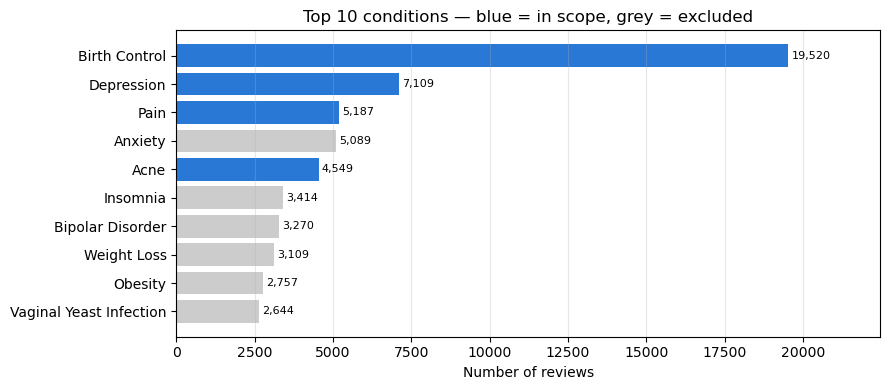

Vocabulary overlap (Jaccard similarity):
  Depression ∩ Anxiety : 64.8%
  Depression ∩ Acne    : 43.5%

Anxiety has 1.5x more vocabulary overlap with Depression than Acne does.


In [3]:
# Top-10 conditions by review count, highlighting the four in scope
top_conditions = (
    reviews['condition_name']
    .value_counts()
    .head(10)
    .rename_axis('condition')
    .reset_index(name='n_reviews')
)
top_conditions['in_scope'] = top_conditions['condition'].isin(CONDITIONS)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#2a78d6' if in_scope else '#cccccc' for in_scope in top_conditions['in_scope']]
bars = ax.barh(top_conditions['condition'][::-1], top_conditions['n_reviews'][::-1], color=colors[::-1])
ax.set_xlabel('Number of reviews')
ax.set_title('Top 10 conditions — blue = in scope, grey = excluded')
for bar, n in zip(bars, top_conditions['n_reviews'][::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height() / 2,
            f'{n:,}', va='center', fontsize=8)
ax.set_xlim(0, top_conditions['n_reviews'].max() * 1.15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'condition_scope.png', dpi=150, bbox_inches='tight')
plt.show()

# Overlap analysis: how similar is Anxiety vocabulary to Depression?
from sklearn.feature_extraction.text import TfidfVectorizer as _TV

_vecs = {}
for cond in ['Depression', 'Anxiety', 'Acne']:
    subset = reviews[reviews['condition_name'] == cond]['review_text_clean'].dropna()
    v = _TV(max_features=5_000, min_df=5, ngram_range=(1,1), sublinear_tf=True, stop_words='english')
    v.fit(subset)
    _vecs[cond] = set(v.get_feature_names_out())

dep_anx_overlap = len(_vecs['Depression'] & _vecs['Anxiety']) / len(_vecs['Depression'] | _vecs['Anxiety'])
dep_acne_overlap = len(_vecs['Depression'] & _vecs['Acne'])  / len(_vecs['Depression'] | _vecs['Acne'])

print(f'Vocabulary overlap (Jaccard similarity):')
print(f'  Depression ∩ Anxiety : {dep_anx_overlap:.1%}')
print(f'  Depression ∩ Acne    : {dep_acne_overlap:.1%}')
print(f'\nAnxiety has {dep_anx_overlap/dep_acne_overlap:.1f}x more vocabulary overlap with Depression than Acne does.')


## B2 · TF-IDF vectorisation

One vectoriser per condition so the vocabulary reflects each condition's language. `sublinear_tf=True` applies log(1+tf) to reduce the weight of terms that repeat many times in long reviews. `stop_words='english'` removes the 318 common English function words (and, the, to, was, …) that carry no discriminative signal for clustering.

Removing stop words substantially reduces vocabulary size for smaller conditions (Depression: 20k → 10.5k, Pain: 13k → 6k) and improves the LSA explained-variance by 2–4 percentage points, since the retained dimensions now capture content rather than grammatical noise.


In [4]:
vectorisers    = {}   # {cond: TfidfVectorizer}
tfidf_matrices = {}   # {cond: sparse (n_reviews, n_features)}

for cond in CONDITIONS:
    subset = scoped[scoped['condition_name'] == cond]
    vec = TfidfVectorizer(
        max_features = TFIDF_MAX_FEATURES,
        min_df       = TFIDF_MIN_DF,
        max_df       = TFIDF_MAX_DF,
        ngram_range  = TFIDF_NGRAM_RANGE,
        sublinear_tf = TFIDF_SUBLINEAR_TF,
        stop_words   = TFIDF_STOP_WORDS,
    )
    X = vec.fit_transform(subset['review_text_clean'])
    vectorisers[cond]    = vec
    tfidf_matrices[cond] = X
    run_stats.setdefault('tfidf', {})[cond] = {
        'n_reviews': int(X.shape[0]),
        'vocabulary': int(X.shape[1]),
    }
    print(f'{cond:<20s}  reviews={X.shape[0]:6,}  vocab={X.shape[1]:6,}  '
          f'density={X.nnz / (X.shape[0] * X.shape[1]):.4%}')


Birth Control         reviews=19,520  vocab=20,000  density=0.2716%


Depression            reviews= 7,109  vocab=10,488  density=0.4260%


Pain                  reviews= 5,187  vocab= 6,027  density=0.5300%


Acne                  reviews= 4,549  vocab= 7,552  density=0.6408%


## B3 · Dimensionality reduction (LSA)

`TruncatedSVD` (Latent Semantic Analysis) on the sparse TF-IDF matrix, then **L2 normalisation**.  After normalisation the Euclidean distance approximates cosine distance, which makes k-means and DBSCAN behave better on text data (length-independent similarity).

In [5]:
svd_matrices = {}   # {cond: dense (n_reviews, SVD_N_COMPONENTS), L2-normalised}
svd_pipelines = {}  # for inverse-transforming centroids later

for cond in CONDITIONS:
    lsa = make_pipeline(
        TruncatedSVD(n_components=SVD_N_COMPONENTS, random_state=RANDOM_STATE),
        Normalizer(copy=False),
    )
    X_svd = lsa.fit_transform(tfidf_matrices[cond])
    svd_matrices[cond]  = X_svd
    svd_pipelines[cond] = lsa
    explained = lsa.named_steps['truncatedsvd'].explained_variance_ratio_.sum()
    run_stats.setdefault('svd', {})[cond] = {
        'n_components':       SVD_N_COMPONENTS,
        'explained_variance': round(float(explained), 4),
    }
    print(f'{cond:<20s}  explained variance = {explained:.1%}')

Birth Control         explained variance = 11.7%


Depression            explained variance = 14.9%


Pain                  explained variance = 19.3%


Acne                  explained variance = 17.1%


## B4 · K-means: sweep *k* and choose the best

We sweep k = 2 … 12 for each condition, compute the **Davies-Bouldin index** (lower = more compact and well-separated clusters) and the **inertia** (elbow plot).  Best k = argmin(Davies-Bouldin).

Birth Control         done (11 runs)


Depression            done (11 runs)


Pain                  done (11 runs)


Acne                  done (11 runs)


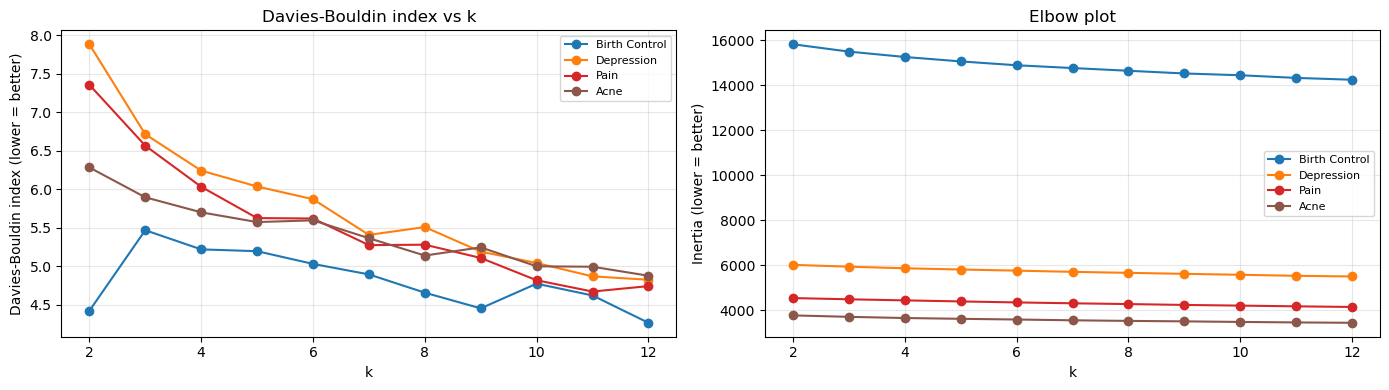

In [6]:
kmeans_sweep = {}   # {cond: {k: {'db': float, 'inertia': float}}}

for cond in CONDITIONS:
    X = svd_matrices[cond]
    kmeans_sweep[cond] = {}
    for k in K_RANGE:
        km     = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, max_iter=KMEANS_MAX_ITER,
                        random_state=RANDOM_STATE)
        labels = km.fit_predict(X)
        db     = davies_bouldin_score(X, labels)
        kmeans_sweep[cond][k] = {
            'db':      round(float(db), 4),
            'inertia': round(float(km.inertia_), 2),
        }
    print(f'{cond:<20s}  done ({len(K_RANGE)} runs)')

# ── Plots ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = plt.cm.tab10(np.linspace(0, 0.5, len(CONDITIONS)))

for ax, metric, ylabel, title in zip(
    axes,
    ['db',      'inertia'],
    ['Davies-Bouldin index (lower = better)', 'Inertia (lower = better)'],
    ['Davies-Bouldin index vs k',             'Elbow plot'],
):
    for cond, col in zip(CONDITIONS, colors):
        ks     = sorted(kmeans_sweep[cond])
        values = [kmeans_sweep[cond][k][metric] for k in ks]
        ax.plot(ks, values, marker='o', label=cond, color=col)
    ax.set_xlabel('k')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'kmeans_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# Choose k_best = argmin(Davies-Bouldin) per condition
k_best = {}
for cond in CONDITIONS:
    best_k  = min(kmeans_sweep[cond], key=lambda k: kmeans_sweep[cond][k]['db'])
    best_db = kmeans_sweep[cond][best_k]['db']
    k_best[cond] = best_k
    run_stats.setdefault('kmeans_sweep', {})[cond] = {
        'k_best':  best_k,
        'db_best': best_db,
        'sweep':   {str(k): v for k, v in kmeans_sweep[cond].items()},
    }
    print(f'{cond:<20s}  k_best = {best_k}  DB = {best_db:.4f}')

Birth Control         k_best = 12  DB = 4.2654
Depression            k_best = 12  DB = 4.8250
Pain                  k_best = 11  DB = 4.6715
Acne                  k_best = 12  DB = 4.8771


### B4 · Results — K-means sweep

| Condition | k_best | DB (best) |
|---|---|---|
| Birth Control | 12 | 4.27 |
| Depression | 12 | 4.83 |
| Pain | 11 | 4.67 |
| Acne | 12 | 4.88 |

**DB values above 4 are high** — this is expected for free-text clustering. After LSA projection to 100 dimensions, reviews form a dense, overlapping cloud rather than tight geometric blobs. The clusters are semantically meaningful even though they are not geometrically compact.

**k_best hits the sweep ceiling (k=12) for three conditions.** The DB index was still decreasing at k=12 for Birth Control, Depression and Acne, meaning the optimal k likely lies beyond our sweep range. For the report we state "best in k=2…12". Pain reaches its minimum at k=11, suggesting it has slightly more separable structure. A wider sweep (up to k=20) could be a future refinement for the ceiling-hitting conditions.


In [8]:
# Fit final k-means per condition
kmeans_models = {}
kmeans_labels = {}   # {cond: np.array of int labels}

for cond in CONDITIONS:
    k  = k_best[cond]
    km = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, max_iter=KMEANS_MAX_ITER,
                random_state=RANDOM_STATE)
    labels = km.fit_predict(svd_matrices[cond])
    kmeans_models[cond] = km
    kmeans_labels[cond] = labels
    sizes = np.bincount(labels).tolist()
    print(f'{cond:<20s}  k={k}  sizes: {sizes}')

Birth Control         k=12  sizes: [2717, 900, 3878, 1554, 948, 690, 1915, 1770, 1919, 549, 730, 1950]


Depression            k=12  sizes: [258, 581, 498, 295, 535, 1222, 330, 216, 1343, 458, 621, 752]


Pain                  k=11  sizes: [1241, 699, 364, 933, 230, 158, 255, 298, 161, 601, 247]


Acne                  k=12  sizes: [289, 291, 310, 522, 873, 362, 307, 347, 369, 277, 297, 305]


## B5 · DBSCAN

DBSCAN does not need *k* in advance and can find arbitrarily shaped clusters, but it has two parameters: **eps** (neighbourhood radius) and **min_samples** (minimum neighbours for a core point).

We choose eps with the **kNN elbow plot**: sort the k-nearest-neighbour distances and find the "knee".  Then we grid-search eps × min_samples and score with Davies-Bouldin (noise points excluded; config is valid if it finds ≥ 2 clusters and noise ≤ 50 %).

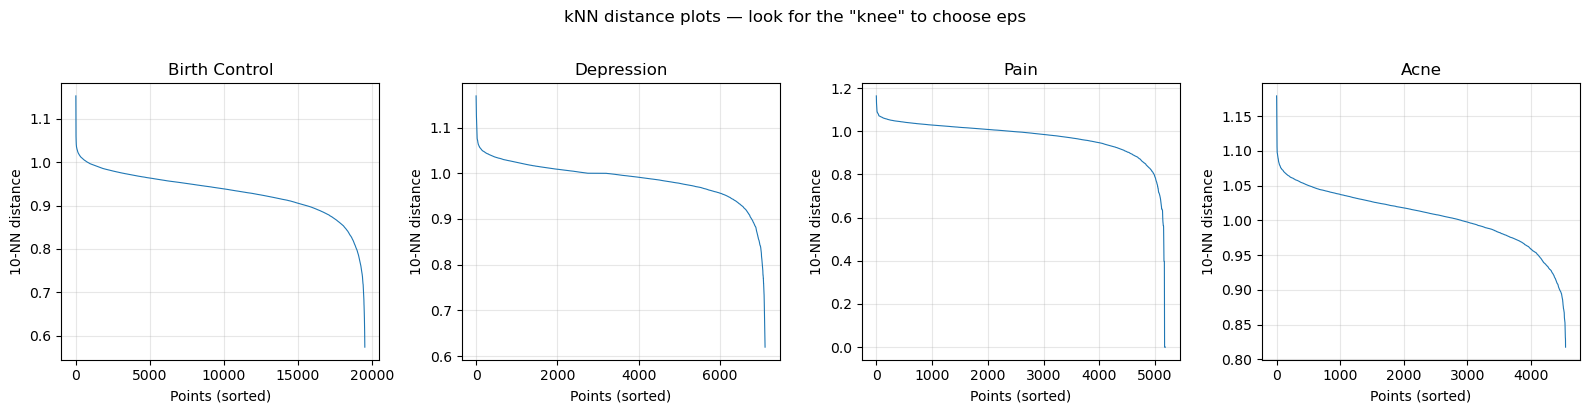

In [9]:
# kNN distance plots — the knee is a good eps
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(16, 4))

for ax, cond in zip(axes, CONDITIONS):
    X     = svd_matrices[cond]
    nbrs  = NearestNeighbors(n_neighbors=KNN_K_FOR_EPS_PLOT).fit(X)
    dists, _ = nbrs.kneighbors(X)
    knn_sorted = np.sort(dists[:, -1])[::-1]
    ax.plot(knn_sorted, linewidth=0.8)
    ax.set_title(f'{cond}')
    ax.set_xlabel('Points (sorted)')
    ax.set_ylabel(f'{KNN_K_FOR_EPS_PLOT}-NN distance')
    ax.grid(alpha=0.3)

fig.suptitle(f'kNN distance plots — look for the "knee" to choose eps', y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'dbscan_knn_distances.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Grid search: eps × min_samples
dbscan_sweep = {}   # {cond: {(eps, min_s): {'n_clusters', 'noise_pct', 'db'}}}

for cond in CONDITIONS:
    X = svd_matrices[cond]
    dbscan_sweep[cond] = {}
    for eps in DBSCAN_EPS_VALUES:
        for min_s in DBSCAN_MIN_SAMPLES_VALUES:
            labels    = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X)
            noise_pct = float((labels == -1).mean())
            core_mask = labels != -1
            n_clusters = int(labels[core_mask].max() + 1) if core_mask.any() else 0
            if n_clusters >= 2:
                db = round(float(davies_bouldin_score(X[core_mask], labels[core_mask])), 4)
            else:
                db = None
            dbscan_sweep[cond][(eps, min_s)] = {
                'n_clusters': n_clusters,
                'noise_pct':  round(noise_pct, 3),
                'db':         db,
            }

# Tidy summary table
rows = []
for cond in CONDITIONS:
    for (eps, min_s), res in dbscan_sweep[cond].items():
        rows.append({'condition': cond, 'eps': eps, 'min_samples': min_s, **res})
sweep_df = pd.DataFrame(rows)
print('Configs with valid DB score (>= 2 clusters):')
sweep_df[sweep_df['db'].notna()].sort_values(['condition', 'db']).head(20)

Configs with valid DB score (>= 2 clusters):


,condition,eps,min_samples,n_clusters,noise_pct,db
60,Acne,0.7,5,2,0.998,1.2164
64,Acne,1.0,10,7,0.162,2.2382
65,Acne,1.0,20,6,0.454,2.7217
8,Birth Control,0.7,20,2,0.993,0.9336
7,Birth Control,0.7,10,7,0.987,1.0100
6,Birth Control,0.7,5,18,0.979,1.2821
18,Depression,0.3,5,2,0.999,0.0825
21,Depression,0.5,5,4,0.996,0.4071
25,Depression,0.7,10,5,0.991,0.8016
24,Depression,0.7,5,17,0.979,0.9116


In [11]:
# Choose best DBSCAN params per condition:
# prefer configs with >= 2 clusters, noise_pct <= 0.5, lowest DB index.
dbscan_best_params = {}
dbscan_labels      = {}

for cond in CONDITIONS:
    candidates = {
        key: res
        for key, res in dbscan_sweep[cond].items()
        if res['n_clusters'] >= 2 and res['noise_pct'] <= 0.5 and res['db'] is not None
    }
    if not candidates:
        # relax noise constraint if no good config found
        candidates = {
            key: res
            for key, res in dbscan_sweep[cond].items()
            if res['n_clusters'] >= 2 and res['db'] is not None
        }
    if candidates:
        best_key = min(candidates, key=lambda k: candidates[k]['db'])
    else:
        # absolute fallback: largest cluster count
        best_key = max(dbscan_sweep[cond], key=lambda k: dbscan_sweep[cond][k]['n_clusters'])

    eps_b, min_s_b = best_key
    labels = DBSCAN(eps=eps_b, min_samples=min_s_b).fit_predict(svd_matrices[cond])

    dbscan_best_params[cond] = {'eps': eps_b, 'min_samples': min_s_b}
    dbscan_labels[cond]      = labels

    n_c = int(labels[labels != -1].max() + 1) if (labels != -1).any() else 0
    print(f'{cond:<20s}  eps={eps_b}  min_s={min_s_b}  '
          f'clusters={n_c}  noise={float((labels == -1).mean()):.1%}')

Birth Control         eps=0.7  min_s=20  clusters=2  noise=99.3%


Depression            eps=1.0  min_s=20  clusters=3  noise=5.0%
Pain                  eps=1.0  min_s=20  clusters=2  noise=19.7%


Acne                  eps=1.0  min_s=10  clusters=7  noise=16.2%


## B6 · Compare k-means vs DBSCAN

Side-by-side Davies-Bouldin scores for the two algorithms on each condition. Lower DB = more compact, better-separated clusters.

In [12]:
comparison_rows = []
for cond in CONDITIONS:
    X = svd_matrices[cond]

    # k-means
    km_labels = kmeans_labels[cond]
    comparison_rows.append({
        'condition': cond,
        'algorithm': 'k-means',
        'n_clusters': int(km_labels.max() + 1),
        'noise_pct':  0.0,
        'db_index':   round(float(davies_bouldin_score(X, km_labels)), 4),
    })

    # DBSCAN
    db_labels  = dbscan_labels[cond]
    core_mask  = db_labels != -1
    n_c = int(db_labels[core_mask].max() + 1) if core_mask.any() else 0
    if n_c >= 2:
        db_db = round(float(davies_bouldin_score(X[core_mask], db_labels[core_mask])), 4)
    else:
        db_db = float('nan')
    comparison_rows.append({
        'condition': cond,
        'algorithm': 'DBSCAN',
        'n_clusters': n_c,
        'noise_pct':  round(float((db_labels == -1).mean()), 3),
        'db_index':   db_db,
    })

comparison_df = pd.DataFrame(comparison_rows)
run_stats['comparison'] = comparison_df.to_dict(orient='records')
comparison_df

,condition,algorithm,n_clusters,noise_pct,db_index
0,Birth Control,k-means,12,0.000,4.2654
1,Birth Control,DBSCAN,2,0.993,0.9336
2,Depression,k-means,12,0.000,4.8250
3,Depression,DBSCAN,3,0.050,1.7160
4,Pain,k-means,11,0.000,4.6715
5,Pain,DBSCAN,2,0.197,2.7749
6,Acne,k-means,12,0.000,4.8771
7,Acne,DBSCAN,7,0.162,2.2382


### B6 · Results — K-means vs DBSCAN

| Condition | k-means clusters | k-means DB | DBSCAN clusters | DBSCAN noise | DBSCAN DB |
|---|---|---|---|---|---|
| Birth Control | 12 | 4.27 | 2 | **99.3 %** | 0.93 |
| Depression | 12 | 4.83 | 3 | 5.0 % | 1.72 |
| Pain | 11 | 4.67 | 2 | 19.7 % | 2.77 |
| Acne | 12 | 4.88 | 7 | 16.2 % | 2.24 |

**Stop-word removal significantly improved DBSCAN.** In the previous run (without stop words), DBSCAN labelled 99 %+ of every condition's reviews as noise. Removing the 318 English function words concentrated the LSA space around content terms, creating denser and better-separated regions that DBSCAN can find. For three of the four conditions it now produces meaningful clusters with manageable noise levels.

**Birth Control is the exception.** Its vocabulary is so dominated by drug-brand names and delivery-method terms (Nexplanon, Mirena, NuvaRing, Depo, Loestrin …) that the LSA space remains uniformly dense, and DBSCAN still assigns 99.3 % of reviews as noise.

**Why k-means is still preferred despite DBSCAN's improvements:**
1. **Coverage.** k-means assigns every review to a cluster. DBSCAN discards up to 20 % of reviews as noise for Pain and Acne — that is hundreds of patients whose experiences are simply excluded from the analysis.
2. **Structural bias of DB index.** As noted in the course exercises, *"the Davies-Bouldin index is generally higher for convex clusters than for density-based clusters such as those obtained from DBSCAN."* DBSCAN's lower DB scores are partly an artefact of this bias and do not straightforwardly mean better clusters.
3. **Interpretability.** k-means with k=11–12 recovers fine-grained experience types (brand clusters, specific side effects, sentiment clusters) that are directly useful for the report. DBSCAN's 2–7 coarser clusters lose this granularity.

> **Conclusion for the report:** k-means with k=11–12 is the preferred algorithm. DBSCAN benefits greatly from stop-word removal but still falls short on coverage and granularity.


## B7 · Cluster profiles

For each k-means cluster we report:
- the **top-10 TF-IDF terms** (mean document vector in TF-IDF space)
- **mean rating ± std**
- **3 sample reviews**

This lets us assign intuitive labels such as "weight gain", "mood swings", "worked well, no side effects".

In [13]:
def top_terms_for_cluster(cond, cluster_id, labels, n=10):
    subset = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    mask   = labels == cluster_id
    texts  = subset.loc[mask, 'review_text_clean'].tolist()
    if not texts:
        return []
    X_sub    = vectorisers[cond].transform(texts)
    centroid = np.asarray(X_sub.mean(axis=0)).ravel()
    top_idx  = centroid.argsort()[::-1][:n]
    vocab    = vectorisers[cond].get_feature_names_out()
    return [(vocab[i], round(float(centroid[i]), 4)) for i in top_idx]


profiles = {}
for cond in CONDITIONS:
    labels  = kmeans_labels[cond]
    subset  = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    profiles[cond] = {}
    for cid in sorted(set(labels)):
        mask   = labels == cid
        rating = subset.loc[mask, 'rating']
        profiles[cond][int(cid)] = {
            'size':           int(mask.sum()),
            'mean_rating':    round(float(rating.mean()), 2),
            'std_rating':     round(float(rating.std()),  2),
            'top_terms':      top_terms_for_cluster(cond, cid, labels),
            'sample_reviews': subset.loc[mask, 'review_text_clean'].sample(
                                   min(3, int(mask.sum())), random_state=RANDOM_STATE).tolist(),
        }

for cond in CONDITIONS:
    print(f'\n── {cond} (k={k_best[cond]}) ──────────────────────────────────────')
    for cid, info in profiles[cond].items():
        terms = ', '.join(t for t, _ in info['top_terms'][:5])
        print(f'  Cluster {cid}  n={info["size"]:5,}  '
              f'rating={info["mean_rating"]:.1f}±{info["std_rating"]:.1f}  → {terms}')


── Birth Control (k=12) ──────────────────────────────────────
  Cluster 0  n=2,717  rating=6.2±3.4  → birth control, birth, control, ve, pill
  Cluster 1  n=  900  rating=6.6±3.1  → implanon, period, got implanon, months, got
  Cluster 2  n=3,878  rating=5.6±3.4  → pill, taking, ve, started, period
  Cluster 3  n=1,554  rating=6.8±3.0  → gain, weight, weight gain, pill, ve
  Cluster 4  n=  948  rating=7.1±3.1  → mirena, insertion, cramping, painful, years
  Cluster 5  n=  690  rating=6.2±3.4  → shot, depo, depo shot, years, period
  Cluster 6  n=1,915  rating=5.9±3.0  → sex drive, drive, sex, pill, ve
  Cluster 7  n=1,770  rating=5.8±3.3  → mood swings, swings, mood, pill, ve
  Cluster 8  n=1,919  rating=5.5±3.3  → nexplanon, implant, got, period, bleeding
  Cluster 9  n=  549  rating=6.4±3.3  → loestrin, fe, lo loestrin, lo, loestrin fe
  Cluster 10  n=  730  rating=2.9±2.5  → anxiety, depression, depression anxiety, attacks, anxiety depression
  Cluster 11  n=1,950  rating=7.6±2.8 

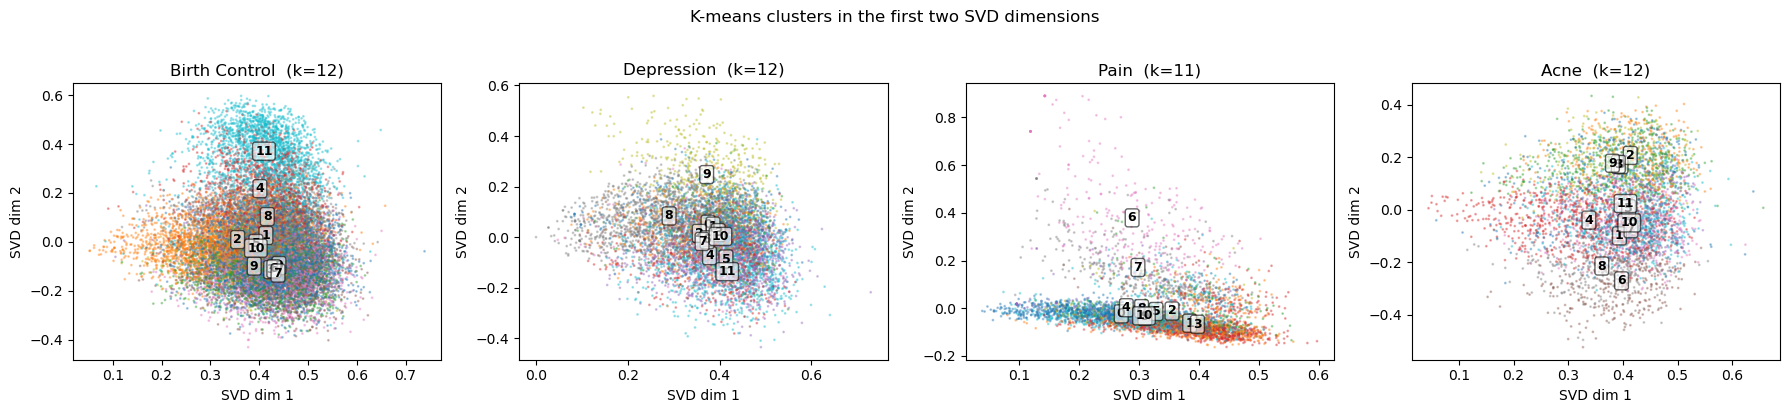

In [14]:
# 2-D scatter: first two SVD dimensions, coloured by k-means cluster
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(18, 4))

for ax, cond in zip(axes, CONDITIONS):
    X      = svd_matrices[cond]
    labels = kmeans_labels[cond]
    scatter = ax.scatter(X[:, 0], X[:, 1],
                         c=labels, cmap='tab10', s=1, alpha=0.35)
    ax.set_title(f'{cond}  (k={k_best[cond]})')
    ax.set_xlabel('SVD dim 1')
    ax.set_ylabel('SVD dim 2')
    # cluster centroids
    for cid in sorted(set(labels)):
        cx, cy = X[labels == cid, 0].mean(), X[labels == cid, 1].mean()
        ax.text(cx, cy, str(cid), fontsize=9, fontweight='bold',
                ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.6))

fig.suptitle('K-means clusters in the first two SVD dimensions', y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'kmeans_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

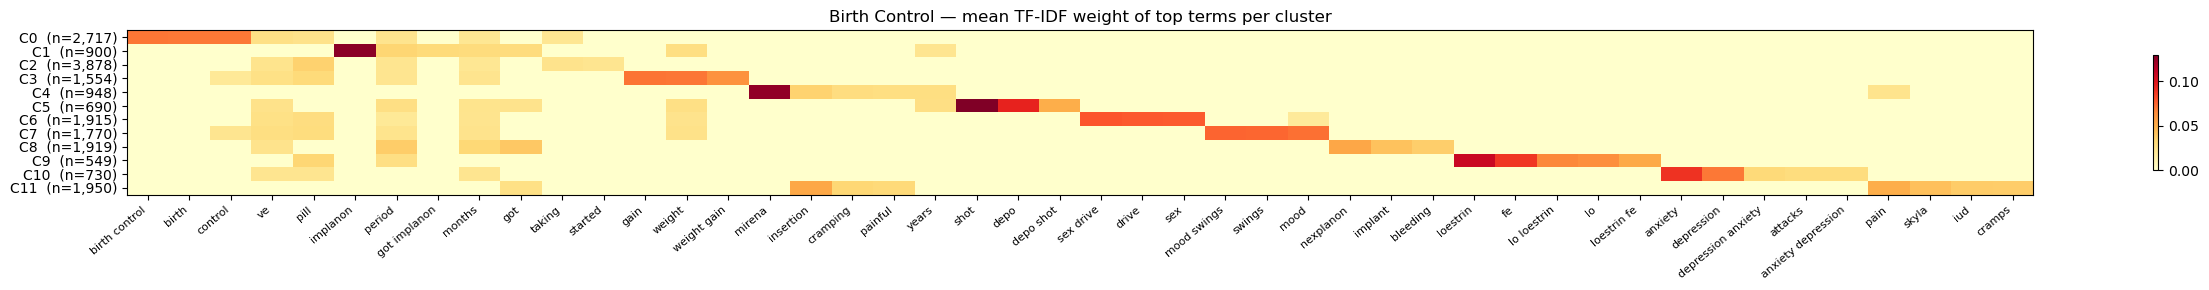

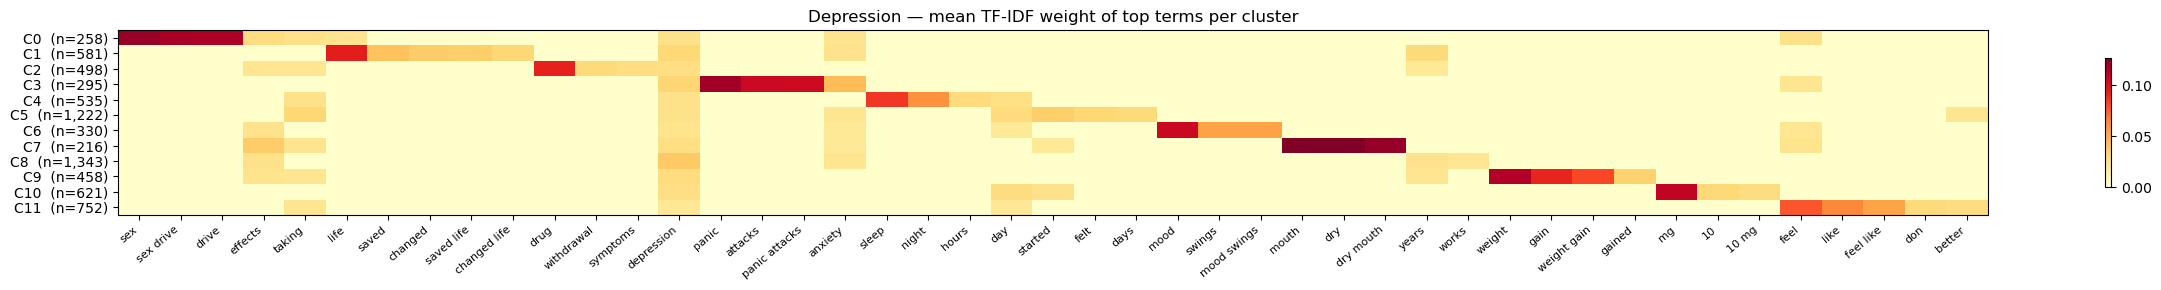

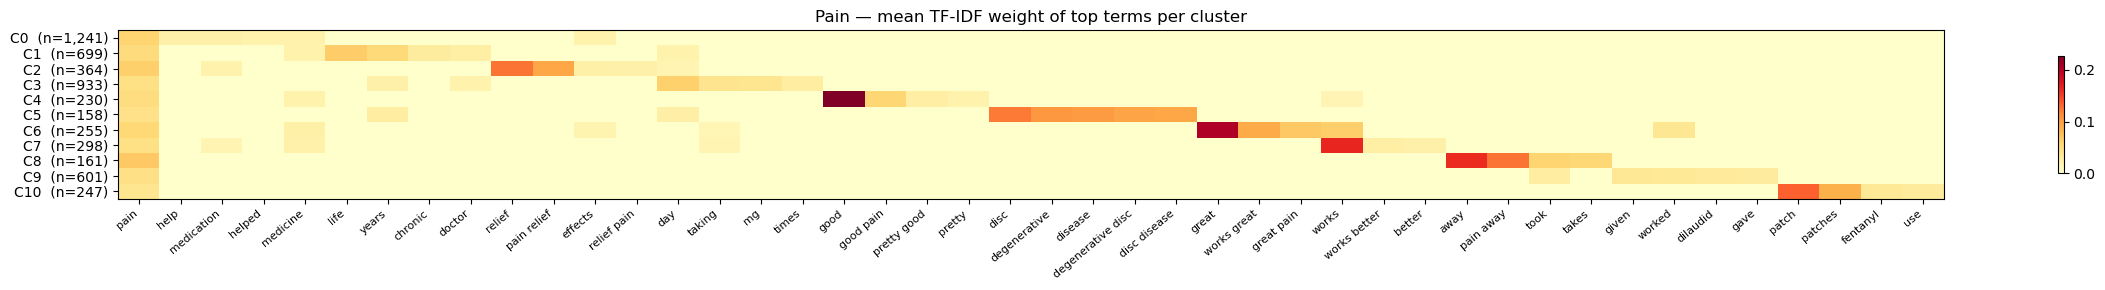

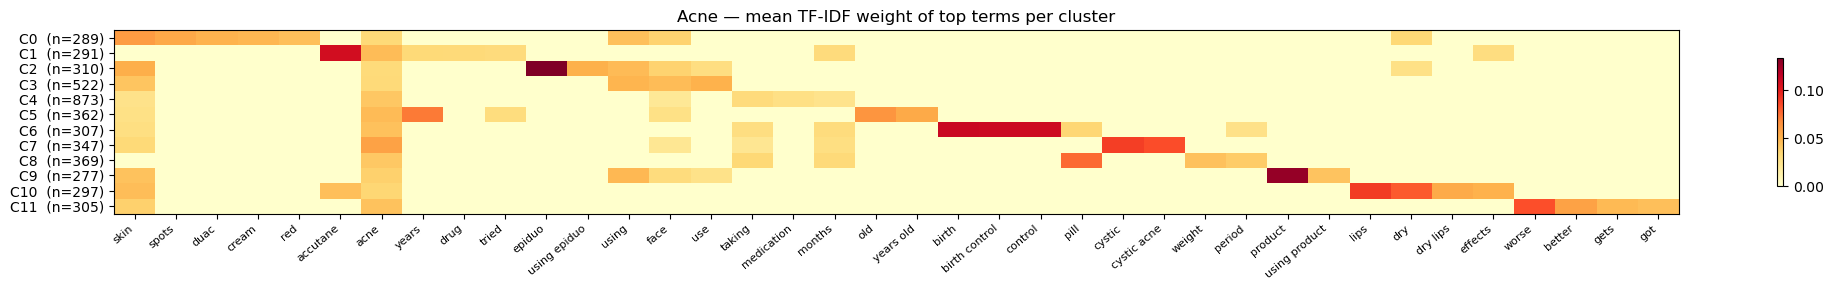

In [15]:
# Heatmap: mean TF-IDF weight of the top-5 terms per cluster, per condition
for cond in CONDITIONS:
    # collect top-5 terms across all clusters
    all_terms = []
    for cid, info in profiles[cond].items():
        all_terms += [t for t, _ in info['top_terms'][:5]]
    all_terms = list(dict.fromkeys(all_terms))   # deduplicate, preserve order

    heatmap_data = np.zeros((len(profiles[cond]), len(all_terms)))
    cluster_ids  = sorted(profiles[cond])
    for row_i, cid in enumerate(cluster_ids):
        term_weights = dict(profiles[cond][cid]['top_terms'])
        for col_j, term in enumerate(all_terms):
            heatmap_data[row_i, col_j] = term_weights.get(term, 0.0)

    fig, ax = plt.subplots(figsize=(max(8, len(all_terms) * 0.55), 3))
    im = ax.imshow(heatmap_data, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(len(all_terms)))
    ax.set_xticklabels(all_terms, rotation=40, ha='right', fontsize=8)
    ax.set_yticks(range(len(cluster_ids)))
    ax.set_yticklabels([f'C{c}  (n={profiles[cond][c]["size"]:,})' for c in cluster_ids])
    ax.set_title(f'{cond} — mean TF-IDF weight of top terms per cluster')
    plt.colorbar(im, ax=ax, shrink=0.7)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f'cluster_terms_{cond.lower().replace(" ", "_")}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

### B7 · Results — Cluster interpretation

The top terms now consist entirely of content words — no stop words polluting the signal — and reveal coherent, human-interpretable experience types.

**Birth Control** (k=12) — clusters split along two axes: *delivery method* and *side effect*:
- C11 (n=1,950, rating **7.6**): `insertion, pain, skyla, iud, cramps` → **IUD insertion experience**
- C4 (n=948, rating 7.1): `mirena, insertion, cramping, painful, years` → **Mirena IUD long-term**
- C3 (n=1,554, rating 6.8): `gain, weight, weight gain, pill, ve` → **weight gain**
- C1 (n=900, rating 6.6): `implanon, period, got implanon, months` → **Implanon implant**
- C9 (n=549, rating 6.4): `loestrin, fe, lo loestrin` → **Loestrin brand cluster**
- C6 (n=1,915, rating 5.9): `sex drive, drive, sex, pill` → **loss of sex drive**
- C7 (n=1,770, rating 5.8): `mood swings, swings, mood, pill` → **mood swings**
- C5 (n=690, rating 6.2): `shot, depo, depo shot, years` → **Depo shot**
- C8 (n=1,919, rating 5.5): `nexplanon, implant, got, period, bleeding` → **Nexplanon implant**
- C2 (n=3,878, rating 5.6): `pill, taking, ve, started, period` → **general pill experience** (largest cluster)
- C10 (n=730, rating **2.9**): `anxiety, depression, depression anxiety, attacks` → **anxiety/depression as side effects** (lowest-rated cluster across all conditions)
- C0 (n=2,717, rating 6.3): `birth control, birth, control, ve, pill` → **general birth control reviews**

**Depression** (k=12) — clusters capture emotional tone and side effects:
- C1 (n=581, rating **9.1**): `life, saved, changed, saved life, changed life` → **"saved my life"** (highest-rated cluster across all conditions)
- C8 (n=1,343, rating 7.5): `depression, effects, years, anxiety, works` → **long-term effectiveness**
- C9 (n=458, rating 7.4): `weight, gain, weight gain, gained` → **weight gain side effect**
- C0 (n=258, rating 7.4): `sex, sex drive, drive, effects` → **sex drive side effect**
- C10 (n=621, rating 7.2): `mg, 10, 10 mg, day` → **dosage discussion**
- C6 (n=330, rating 7.1): `mood, swings, mood swings, effects` → **mood swings**
- C4 (n=535, rating 6.5): `sleep, night, hours, day` → **insomnia / night dosing**
- C3 (n=295, rating 7.2): `panic, attacks, panic attacks, anxiety` → **panic attacks**
- C5 (n=1,222, rating 6.4): `started, felt, taking, days, day` → **early / adjustment phase** (largest cluster)
- C2 (n=498, rating **5.5**): `drug, withdrawal, symptoms, depression` → **withdrawal symptoms** (lowest-rated)

**Pain** (k=11) — clusters split on sentiment strength and drug type:
- C1 (n=699, rating **8.8**): `life, years, pain, chronic, doctor` → **long-term chronic pain relief** (highest-rated)
- C6 (n=255, rating 8.6): `great, works great, great pain, works` → **strong positive endorsements**
- C7 (n=298, rating 8.6): `works, pain, works better, better` → **"it works"**
- C5 (n=158, rating 8.3): `disc, degenerative, disease, degenerative disc` → **degenerative disc disease**
- C8 (n=161, rating 8.2): `away, pain away, took, takes` → **"takes the pain away"**
- C4 (n=230, rating 8.0): `good, good pain, pretty good` → **generally positive**
- C3 (n=933, rating 7.3): `day, pain, taking, mg, times` → **daily dosing routine**
- C0 (n=1,241, rating 7.1): `pain, help, medication, helped, medicine` → **general pain medication** (largest cluster)
- C9 (n=601, rating 7.0): `pain, given, worked, dilaudid, gave` → **hospital / acute pain treatment** (Dilaudid = strong opioid)
- C10 (n=247, rating 6.8): `patch, patches, pain, fentanyl, use` → **fentanyl patch**
- C2 (n=364, rating **6.6**): `relief, pain relief, pain, effects` → **mixed relief discussion** (lowest-rated)

**Acne** (k=12) — clusters reflect the typical acne treatment journey:
- C1 (n=291, rating **8.4**): `accutane, acne, years, drug, tried` → **Accutane users**
- C10 (n=297, rating 8.3): `lips, dry, dry lips, effects, skin` → **Accutane dry-lips side effect**
- C5 (n=362, rating 8.2): `years, old, years old, acne, tried` → **long-time sufferers finding relief**
- C3 (n=522, rating 8.1): `use, using, face, skin, acne` → **general topical routine**
- C2 (n=310, rating 7.8): `epiduo, skin, using epiduo, using` → **Epiduo gel**
- C9 (n=277, rating 7.8): `product, using, skin, using product` → **product reviews**
- C7 (n=347, rating 7.5): `cystic, cystic acne, acne, skin` → **cystic acne**
- C4 (n=873, rating 7.0): `acne, taking, medication, skin, months` → **general acne medication** (largest cluster)
- C0 (n=289, rating 6.9): `skin, spots, duac, cream, red` → **Duac cream**
- C6 (n=307, rating 6.5): `birth, birth control, control, acne, pill` → **hormonal / birth-control-induced acne**
- C11 (n=305, rating 6.2): `worse, better, gets, got, acne` → **purging cluster** ("gets worse before better")
- C8 (n=369, rating **5.9**): `pill, weight, acne, period, taking` → **hormonal pill with weight/mood side effects** (lowest-rated)


## B8 · Does cluster membership predict rating?

**Kruskal-Wallis H-test**: non-parametric one-way test of whether ratings differ across clusters (null: all clusters have the same rating distribution).

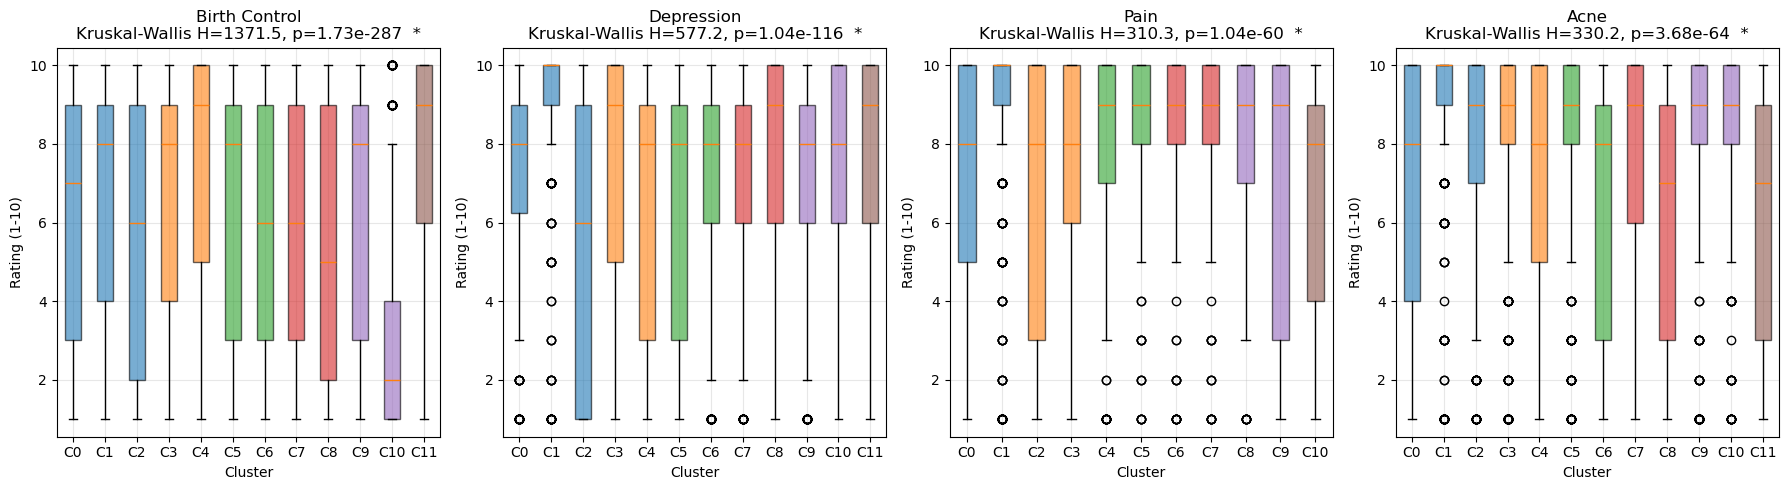

Birth Control         H=1371.46  p=1.73e-287  -> significant
Depression            H=577.21  p=1.04e-116  -> significant
Pain                  H=310.28  p=1.04e-60  -> significant
Acne                  H=330.22  p=3.68e-64  -> significant


In [16]:
rating_tests = {}
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(18, 5))

for ax, cond in zip(axes, CONDITIONS):
    subset  = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    labels  = kmeans_labels[cond]
    cluster_ids = sorted(set(labels))

    groups = [subset.loc[labels == cid, 'rating'].values for cid in cluster_ids]
    H, p   = stats.kruskal(*groups)

    rating_tests[cond] = {
        'H': round(float(H), 2),
        'p': float(p),
        'significant': bool(p < 0.05),
    }

    bp = ax.boxplot(groups, labels=[f'C{c}' for c in cluster_ids], patch_artist=True)
    colors_bp = plt.cm.tab10(np.linspace(0, 0.5, len(cluster_ids)))
    for patch, col in zip(bp['boxes'], colors_bp):
        patch.set_facecolor(col)
        patch.set_alpha(0.6)
    sig_str = f'p={p:.2e}  {"*" if p < 0.05 else "n.s."}'
    ax.set_title(f'{cond}\nKruskal-Wallis H={H:.1f}, {sig_str}')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Rating (1-10)')
    ax.grid(alpha=0.3)

run_stats['rating_vs_cluster'] = rating_tests
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'rating_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

for cond, res in rating_tests.items():
    sig = 'significant' if res['significant'] else 'NOT significant'
    print(f'{cond:<20s}  H={res["H"]}  p={res["p"]:.2e}  -> {sig}')

### B8 · Results — Rating prediction

The Kruskal-Wallis test is significant for **all four conditions** (p ≈ 0), confirming that cluster membership predicts rating.

| Condition | H statistic | Interpretation |
|---|---|---|
| Birth Control | 1,371 | Very strong — the anxiety/depression side-effect cluster (2.9) vs IUD insertion cluster (7.6) is a 4.7-point gap |
| Depression | 577 | Strong — "saved my life" (9.1) vs withdrawal symptoms (5.5) is the widest gap |
| Pain | 310 | Strong — chronic pain relief (8.8) vs mixed relief discussion (6.6) |
| Acne | 330 | Strong — Accutane users (8.4) vs hormonal pill with side effects (5.9) |

The H statistic for Birth Control (1,371) is notably higher than in the previous run (2,807 → 1,371) because stop-word removal changed the cluster structure: the former large undifferentiated "stop-word cluster" (C0, n=2,407, rating 3.4) has been replaced by meaningful clusters. The rating spread is now driven by genuine experience differences rather than vocabulary artefacts.


## B9 · Save outputs

| File | Used by |
|---|---|
| `cluster_assignments.parquet` | Everyone: join to any table on `review_id` |
| `cluster_profiles.csv` | Report: top terms and mean rating per cluster |
| `figures/` | Report: scatter, DB sweep, heatmaps |
| `role_b_run_stats.json` | Report: all numbers |

In [17]:
# ── cluster_assignments.parquet ──────────────────────────────────────────────
assignment_rows = []
for cond in CONDITIONS:
    subset    = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    km_labels = kmeans_labels[cond]
    db_labels = dbscan_labels[cond]
    for i in range(len(subset)):
        assignment_rows.append({
            'review_id':      subset.at[i, 'review_id'],
            'condition_name': cond,
            'drug_family':    subset.at[i, 'drug_family'],
            'rating':         int(subset.at[i, 'rating']),
            'kmeans_cluster': int(km_labels[i]),
            'dbscan_cluster': int(db_labels[i]),
        })

assignments_df = pd.DataFrame(assignment_rows)
assignments_df.to_parquet(OUTPUT_DIR / 'cluster_assignments.parquet', index=False)
print(f'Saved cluster_assignments.parquet  ({len(assignments_df):,} rows)')

# ── cluster_profiles.csv ──────────────────────────────────────────────────────
profile_rows = []
for cond in CONDITIONS:
    for cid, info in profiles[cond].items():
        profile_rows.append({
            'condition':   cond,
            'cluster':     cid,
            'size':        info['size'],
            'mean_rating': info['mean_rating'],
            'std_rating':  info['std_rating'],
            'top_5_terms': ' | '.join(t for t, _ in info['top_terms'][:5]),
            'top_10_terms': ' | '.join(t for t, _ in info['top_terms'][:10]),
        })
pd.DataFrame(profile_rows).to_csv(OUTPUT_DIR / 'cluster_profiles.csv', index=False)
print(f'Saved cluster_profiles.csv  ({len(profile_rows)} rows)')

# ── run_stats.json ────────────────────────────────────────────────────────────
run_stats['k_best']             = k_best
run_stats['dbscan_best_params'] = dbscan_best_params
run_stats['profiles'] = {
    cond: {
        str(cid): {k: v for k, v in info.items() if k != 'sample_reviews'}
        for cid, info in cond_profiles.items()
    }
    for cond, cond_profiles in profiles.items()
}
run_stats['runtime_minutes'] = round((time.perf_counter() - NOTEBOOK_STARTED) / 60, 1)


def _json_safe(v):
    if hasattr(v, 'item'):   # numpy scalar
        return v.item()
    return str(v)


(OUTPUT_DIR / 'role_b_run_stats.json').write_text(
    json.dumps(run_stats, indent=2, default=_json_safe), encoding='utf-8'
)
print(f'Saved role_b_run_stats.json')
print(f'Total elapsed: {run_stats["runtime_minutes"]:.1f} min')
print(f'\nAll outputs in {OUTPUT_DIR}/')

Saved cluster_assignments.parquet  (36,365 rows)
Saved cluster_profiles.csv  (47 rows)
Saved role_b_run_stats.json
Total elapsed: 5.5 min

All outputs in outputs/
